# KNN (K-Nearest Neighbors)
## Import Library

In [1]:
# Maftuh Faisal_202431163
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
# Maftuh Faisal_202431163
data = pd.read_csv("premier_league_complete_stats_2025-26.csv")
display(data.head())
data.info()
display(data.describe())

,player_name,team_name,position,accurateChippedPasses,accurateCrosses,accurateCrossesPercentage,accurateFinalThirdPasses,accurateLongBalls,accurateLongBallsPercentage,accurateOppositionHalfPasses,...,totalLongBalls,totalOppositionHalfPasses,totalOwnHalfPasses,totalPasses,totalShots,totwAppearances,touches,wasFouled,yellowCards,yellowRedCards
0,Declan Rice,Arsenal,M,64,45,27.108434,501,81,49.090909,982,...,165,1166,832,1998,40,3,2591,9,3,0
1,Gabriel Magalhães,Arsenal,D,41,1,20.000000,196,73,45.341615,555,...,161,684,919,1603,24,5,1994,30,4,0
2,Bukayo Saka,Arsenal,F,15,37,32.173913,314,14,35.897436,441,...,39,583,135,718,66,5,1287,51,1,0
3,Martín Zubimendi,Arsenal,M,48,2,18.181818,391,51,47.663551,881,...,107,1049,774,1823,27,2,2206,13,4,0
4,William Saliba,Arsenal,D,26,4,44.444444,245,55,50.000000,651,...,110,747,1214,1961,5,0,2243,15,1,0


<class 'pandas.DataFrame'>
RangeIndex: 526 entries, 0 to 525
Columns: 106 entries, player_name to yellowRedCards
dtypes: float64(16), int64(87), str(3)
memory usage: 435.7 KB


,accurateChippedPasses,accurateCrosses,accurateCrossesPercentage,accurateFinalThirdPasses,accurateLongBalls,accurateLongBallsPercentage,accurateOppositionHalfPasses,accurateOwnHalfPasses,accuratePasses,accuratePassesPercentage,...,totalLongBalls,totalOppositionHalfPasses,totalOwnHalfPasses,totalPasses,totalShots,totwAppearances,touches,wasFouled,yellowCards,yellowRedCards
count,526.000000,526.000000,526.000000,526.000000,526.000000,526.000000,526.000000,526.000000,526.000000,526.000000,...,526.000000,526.000000,526.000000,526.000000,526.00000,526.000000,526.000000,526.000000,526.000000,526.000000
mean,17.870722,5.631179,16.666453,116.520913,27.695817,41.645712,235.247148,243.342205,478.589354,79.365846,...,66.205323,311.129278,269.357414,580.486692,16.48289,0.731939,837.114068,13.796578,2.490494,0.024715
std,21.644100,9.309335,17.498741,115.278439,39.781435,21.688612,223.099986,266.091221,452.047147,13.042714,...,107.852579,269.212323,284.603426,520.366976,18.51534,1.183380,683.474746,13.733326,2.536384,0.155402
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,2.000000,0.000000,0.000000,26.000000,3.000000,30.980088,55.250000,40.000000,101.750000,75.420265,...,7.000000,79.000000,49.250000,132.250000,2.00000,0.000000,225.750000,2.000000,0.000000,0.000000
50%,10.000000,1.000000,16.666667,87.000000,14.000000,42.857143,185.500000,149.000000,366.500000,81.956230,...,31.500000,265.000000,174.000000,461.000000,11.00000,0.000000,737.500000,10.000000,2.000000,0.000000
75%,25.000000,7.000000,27.001040,167.000000,36.000000,53.846154,343.000000,364.500000,698.250000,86.847593,...,77.000000,464.000000,408.500000,861.000000,23.00000,1.000000,1273.750000,21.000000,4.000000,0.000000
max,142.000000,58.000000,100.000000,616.000000,338.000000,100.000000,1080.000000,1498.000000,2298.000000,100.000000,...,829.000000,1303.000000,1564.000000,2574.000000,119.00000,6.000000,3039.000000,74.000000,10.000000,1.000000


In [3]:
# Maftuh Faisal_202431163
print(data['position'].value_counts())

position
M    210
D    177
F    101
G     38
Name: count, dtype: int64


In [4]:
# Maftuh Faisal_202431163
fitur = ['goals', 'assists', 'shotsOnTarget', 'keyPasses',
         'tackles', 'interceptions', 'clearances', 'saves']
df_clean = data[fitur + ['position']].copy()
print("Missing values:\n", df_clean.isna().sum())
df_clean = df_clean.dropna()

Missing values:
 goals            0
assists          0
shotsOnTarget    0
keyPasses        0
tackles          0
interceptions    0
clearances       0
saves            0
position         0
dtype: int64


In [5]:
# Maftuh Faisal_202431163
x = df_clean[fitur]
y = df_clean['position']
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, random_state=0, stratify=y
)
print(f"Jumlah data latih: {len(x_train)}, Jumlah data uji: {len(x_test)}")

Jumlah data latih: 394, Jumlah data uji: 132


In [6]:
# Maftuh Faisal_202431163
print("Minimum fitur latih:\n", x_train.min())
print("\nMaksimum fitur latih:\n", x_train.max())

Minimum fitur latih:
 goals            0
assists          0
shotsOnTarget    0
keyPasses        0
tackles          0
interceptions    0
clearances       0
saves            0
dtype: int64

Maksimum fitur latih:
 goals             25
assists           11
shotsOnTarget     54
keyPasses         65
tackles          113
interceptions     56
clearances       237
saves            127
dtype: int64


In [7]:
# Maftuh Faisal_202431163
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

param_grid = {'knn__n_neighbors': range(1, 20)}
grid = GridSearchCV(pipe, param_grid, cv=5, scoring='accuracy')
grid.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'knn__n_neighbors': range(1, 20)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fit

In [8]:
# Maftuh Faisal_202431163
print("Nilai k terbaik:", grid.best_params_)
print("Skor validasi silang terbaik:", round(grid.best_score_, 4))

Nilai k terbaik: {'knn__n_neighbors': 17}
Skor validasi silang terbaik: 0.7436


In [9]:
# Maftuh Faisal_202431163
best_model = grid.best_estimator_
y_pred = best_model.predict(x_test)

In [10]:
# Maftuh Faisal_202431163
print("Accuracy Score:", round(accuracy_score(y_test, y_pred), 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy Score: 0.75

Confusion Matrix:
 [[35  0  0  9]
 [ 2 10  0 13]
 [ 0  0  9  1]
 [ 5  3  0 45]]

Classification Report:
               precision    recall  f1-score   support

           D       0.83      0.80      0.81        44
           F       0.77      0.40      0.53        25
           G       1.00      0.90      0.95        10
           M       0.66      0.85      0.74        53

    accuracy                           0.75       132
   macro avg       0.82      0.74      0.76       132
weighted avg       0.76      0.75      0.74       132



### Prediksi data baru

In [11]:
# 202431163_Maftuh Faisal
x_new = pd.DataFrame([[2, 3, 10, 40, 25, 20, 15, 0]], columns=fitur)
print("Prediksi data baru:", best_model.predict(x_new))

Prediksi data baru: ['M']


## Visualisasi

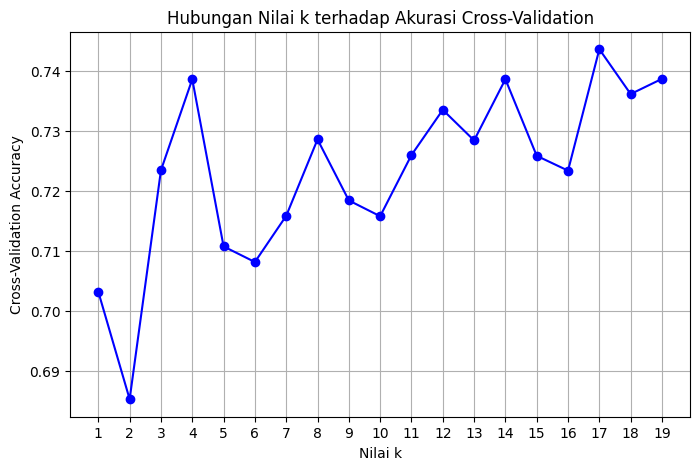

In [13]:
# Langkah 12: Visualisasi Hubungan Nilai k dengan Skor Validasi Silang
k_range = list(range(1, 20))
cv_scores = grid.cv_results_['mean_test_score']

plt.figure(figsize=(8, 5))
plt.plot(k_range, cv_scores, marker='o', linestyle='-', color='b')
plt.title('Hubungan Nilai k terhadap Akurasi Cross-Validation')
plt.xlabel('Nilai k')
plt.ylabel('Cross-Validation Accuracy')
plt.xticks(k_range)
plt.grid(True)
plt.show()